# Gram matrix heatmap analysis (ipci vs mpci, SMAX 3m hard)

Loads one trained `ipci` and one trained `mpci` checkpoint (SMAX `3m`, "hard" target-window constraint), collects a rollout with the trained actor, and visualizes the per-agent product-kernel Gram matrices that `JAXRPCIAlgorithm._compute_gram` builds from standardized per-feature RBF kernels.

In [1]:
import importlib
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


def resolve_repo_root() -> Path:
    cwd = Path.cwd().resolve()
    for candidate in (cwd, *cwd.parents):
        if (candidate / "main.py").is_file() and (candidate / "configs").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the pci_marl repo root from the current notebook working directory.")


ROOT = resolve_repo_root()
FIGURES_DIR = ROOT / "figures"
CHECKPOINTS_DIR = ROOT / "SMAX_checkpts"

for path in (ROOT, FIGURES_DIR):
    path_str = str(path)
    if path_str not in sys.path:
        sys.path.insert(0, path_str)

command_buffer_flag = "--xla_gpu_enable_command_buffer="
existing_xla_flags = os.environ.get("XLA_FLAGS", "")
if command_buffer_flag not in existing_xla_flags:
    os.environ["XLA_FLAGS"] = f"{existing_xla_flags} {command_buffer_flag}".strip()
os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")

import tab2_smax_checkpoint_eval_utils as scu
scu = importlib.reload(scu)

bootstrap_project = scu.bootstrap_project
discover_runs = scu.discover_runs
build_trainer_for_run = scu.build_trainer_for_run

DEVICE = "cuda"

bootstrap_project(DEVICE)
runs_df = discover_runs(CHECKPOINTS_DIR, project_filter=None)
print(f"Repo root: {ROOT}")
print(f"Discovered {len(runs_df)} runs under {CHECKPOINTS_DIR}")


Repo root: /home/chamjin/pci_marl
Discovered 300 runs under /home/chamjin/pci_marl/SMAX_checkpts


In [2]:
IPCI_RUN_DIR = CHECKPOINTS_DIR / "3m" / "hard" / "ipci" / "20260617_043532_seed42"
MPCI_RUN_DIR = CHECKPOINTS_DIR / "3m" / "hard" / "mpci" / "20260617_043232_seed42"

def select_run(run_dir: Path) -> pd.Series:
    matches = runs_df[runs_df["run_dir"].map(lambda p: Path(p) == run_dir)]
    if len(matches) != 1:
        raise AssertionError(f"Expected exactly one run for {run_dir}, found {len(matches)}")
    return matches.iloc[0]

ipci_row = select_run(IPCI_RUN_DIR)
mpci_row = select_run(MPCI_RUN_DIR)

display(pd.DataFrame([ipci_row, mpci_row])[["map_name", "constraint_key", "model_label", "algorithm_type", "seed", "run_dir"]])


,map_name,constraint_key,model_label,algorithm_type,seed,run_dir
74,3m,tar_w=2,pci-ippo,jax_pci_ippo,42,/home/chamjin/pci_marl/SMAX_checkpts/3m/hard/i...
79,3m,tar_w=2,pci-mappo,jax_pci_mappo,42,/home/chamjin/pci_marl/SMAX_checkpts/3m/hard/m...


In [3]:
import jax

N_ENVS = 8
HORIZON = 64
CAUSAL_BATCH_KEYS = ("z", "w", "x_obs", "x_hid", "actions", "targets", "agent_ids", "loss_mask")


def collect_gram_for_run(run_row: pd.Series, *, n_envs: int = N_ENVS, horizon: int = HORIZON):
    """Load a checkpoint, collect an on-policy rollout, and compute the per-agent Gram matrices."""
    trainer, checkpoint_path, cfg = build_trainer_for_run(
        run_row,
        checkpoint_choice="final",
        device=DEVICE,
        eval_episodes=1,
        eval_batch_envs=n_envs,
    )

    algorithm = trainer.algorithm
    _, _, _, _, _, rollout, _ = algorithm.collect_rollout(
        env=trainer.env,
        env_rng=trainer._env_rng,
        action_rng=None,
        batch_states=trainer._batch_env_state,
        obs=trainer._current_obs,
        avail_actions=trainer._current_avail,
        runner_state=trainer._runner_state,
        horizon=horizon,
    )

    causal_batch = algorithm._causal_batch(rollout)
    batch = {k: causal_batch[k] for k in CAUSAL_BATCH_KEYS}
    gram_pa, reg_gram_pa, gram_metrics = algorithm._compute_gram(batch, True)

    result = {
        "gram_pa": np.asarray(jax.device_get(gram_pa)),
        "reg_gram_pa": np.asarray(jax.device_get(reg_gram_pa)),
        "gram_metrics": {k: float(v) for k, v in jax.device_get(gram_metrics).items()},
        "num_agents": algorithm.num_agents,
        "obs_dim": algorithm.obs_dim,
        "action_dim": algorithm.action_dim,
        "bridge_hidden_dim": algorithm.bridge_hidden_dim,
        "bridge_prev_action_dim": algorithm.bridge_prev_action_dim,
        "checkpoint_path": str(checkpoint_path),
        "B_n": int(causal_batch["z"].shape[0]) // algorithm.num_agents,
        # Keep the raw (numpy) causal-batch arrays around for the per-feature
        # component breakdown below — small enough (B, d) tensors to hold in host memory.
        "batch_np": {k: np.asarray(jax.device_get(v)) for k, v in batch.items()},
    }
    return result


print("Collecting ipci rollout + Gram matrices...")
ipci_result = collect_gram_for_run(ipci_row)
print(f"  B_n (samples per agent) = {ipci_result['B_n']}, gram_pa shape = {ipci_result['gram_pa'].shape}")

print("Collecting mpci rollout + Gram matrices...")
mpci_result = collect_gram_for_run(mpci_row)
print(f"  B_n (samples per agent) = {mpci_result['B_n']}, gram_pa shape = {mpci_result['gram_pa'].shape}")

RESULTS = {"ipci": ipci_result, "mpci": mpci_result}


[SMAXWrapper] '3m': 3 allies vs 3 enemies
[SMAXBatchWrapper] '3m': 3v3, n_envs=8
[SMAXBatchWrapper] allowed_targets (full source-level damage mask, window=2): {0: [0, 1], 1: [1, 2], 2: [2, 0]}
[SMAXBatchWrapper] obs_dim=75, action_dim=8
[SMAXBatchWrapper] 3v3 × 8 emvs
[INFO] add_agent_id enabled: base_obs_dim=75, effective_obs_dim=78


  B_n (samples per agent) = 512, gram_pa shape = (3, 512, 512)
[SMAXWrapper] '3m': 3 allies vs 3 enemies
[SMAXBatchWrapper] '3m': 3v3, n_envs=8
[SMAXBatchWrapper] allowed_targets (full source-level damage mask, window=2): {0: [0, 1], 1: [1, 2], 2: [2, 0]}
[SMAXBatchWrapper] obs_dim=75, action_dim=8
[SMAXBatchWrapper] 3v3 × 8 emvs
[INFO] add_agent_id enabled: base_obs_dim=75, effective_obs_dim=78


  B_n (samples per agent) = 512, gram_pa shape = (3, 512, 512)


In [4]:
METRIC_KEYS = (
    "Kz_offdiag_mean",
    "Kz_offdiag_std",
    "K_effective_rank_norm_mean",
    "K_eig_top1_frac_mean",
    "K_eig_log_condition_mean",
)

metrics_table = pd.DataFrame(
    {name: {k: res["gram_metrics"].get(k) for k in METRIC_KEYS} for name, res in RESULTS.items()}
).T
metrics_table.index.name = "algorithm"
display(metrics_table)


,Kz_offdiag_mean,Kz_offdiag_std,K_effective_rank_norm_mean,K_eig_top1_frac_mean,K_eig_log_condition_mean
algorithm,,,,,
ipci,0.005278,0.039760,0.763285,0.024274,19.449017
mpci,0.006099,0.041381,0.794305,0.033025,19.106190


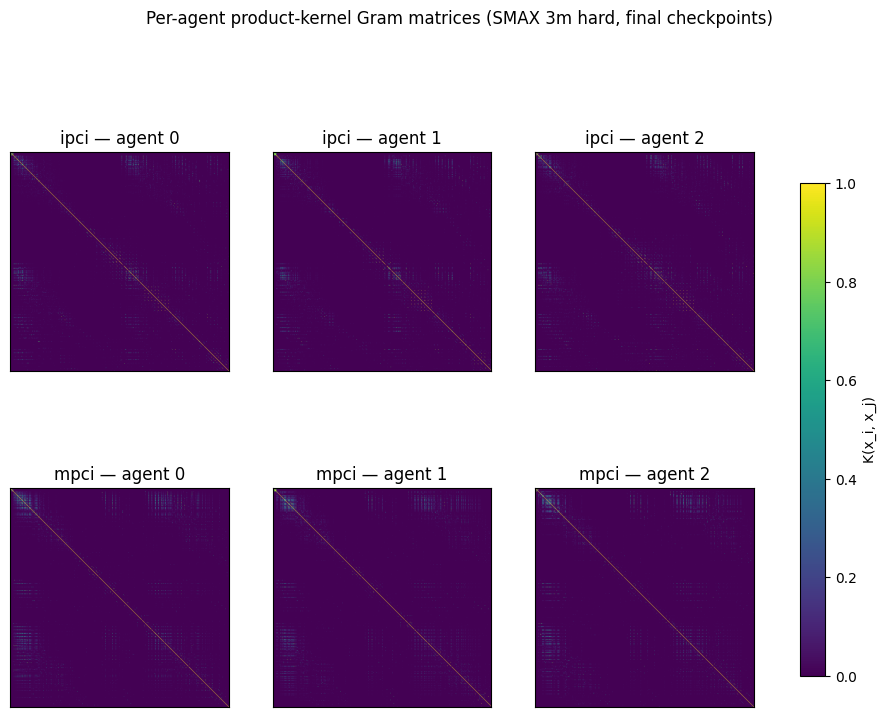

In [5]:
algo_names = list(RESULTS.keys())
num_agents = RESULTS[algo_names[0]]["num_agents"]

fig, axes = plt.subplots(
    len(algo_names), num_agents,
    figsize=(4 * num_agents, 4 * len(algo_names)),
    squeeze=False,
)

im = None
for row, algo in enumerate(algo_names):
    gram_pa = RESULTS[algo]["gram_pa"]
    for agent in range(num_agents):
        ax = axes[row][agent]
        im = ax.imshow(gram_pa[agent], cmap="viridis", vmin=0.0, vmax=1.0)
        ax.set_title(f"{algo} — agent {agent}")
        ax.set_xticks([])
        ax.set_yticks([])

fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.8, label="K(x_i, x_j)")
fig.suptitle("Per-agent product-kernel Gram matrices (SMAX 3m hard, final checkpoints)", y=1.02)
plt.show()


Off-diagonal stats pooled across both algorithms / all agents: mean=0.00550, std=0.03992, max=0.99825, 99th pct (used as vmax below)=0.11766


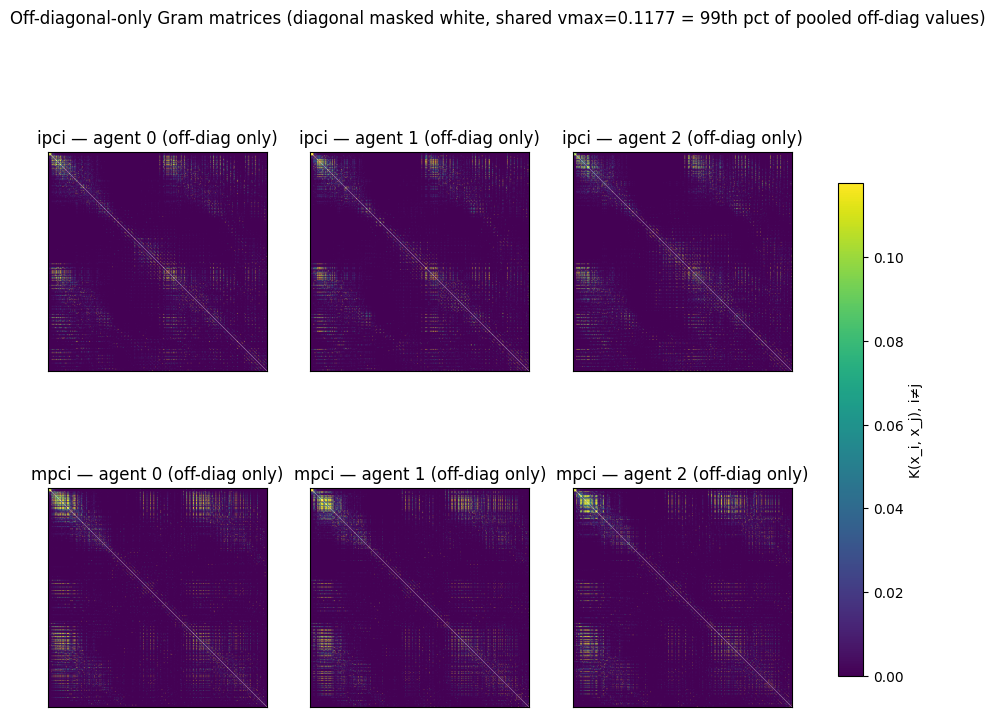

In [6]:
offdiag_mask = ~np.eye(RESULTS[algo_names[0]]["gram_pa"].shape[-1], dtype=bool)
pooled_offdiag = np.concatenate(
    [RESULTS[algo]["gram_pa"][agent][offdiag_mask] for algo in algo_names for agent in range(num_agents)]
)
vmax_shared = float(np.percentile(pooled_offdiag, 99))
print(
    f"Off-diagonal stats pooled across both algorithms / all agents: "
    f"mean={pooled_offdiag.mean():.5f}, std={pooled_offdiag.std():.5f}, "
    f"max={pooled_offdiag.max():.5f}, 99th pct (used as vmax below)={vmax_shared:.5f}"
)

cmap_offdiag = plt.cm.viridis.copy()
cmap_offdiag.set_bad(color="white")

fig, axes = plt.subplots(
    len(algo_names), num_agents,
    figsize=(4 * num_agents, 4 * len(algo_names)),
    squeeze=False,
)

im = None
for row, algo in enumerate(algo_names):
    gram_pa = RESULTS[algo]["gram_pa"]
    for agent in range(num_agents):
        K_offdiag = gram_pa[agent].copy()
        np.fill_diagonal(K_offdiag, np.nan)  # mask the diagonal so it doesn't dominate the color scale
        ax = axes[row][agent]
        im = ax.imshow(K_offdiag, cmap=cmap_offdiag, vmin=0.0, vmax=vmax_shared)
        ax.set_title(f"{algo} — agent {agent} (off-diag only)")
        ax.set_xticks([])
        ax.set_yticks([])

fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.8, label="K(x_i, x_j), i≠j")
fig.suptitle(
    f"Off-diagonal-only Gram matrices (diagonal masked white, shared vmax={vmax_shared:.4f} = 99th pct of pooled off-diag values)",
    y=1.02,
)
plt.show()


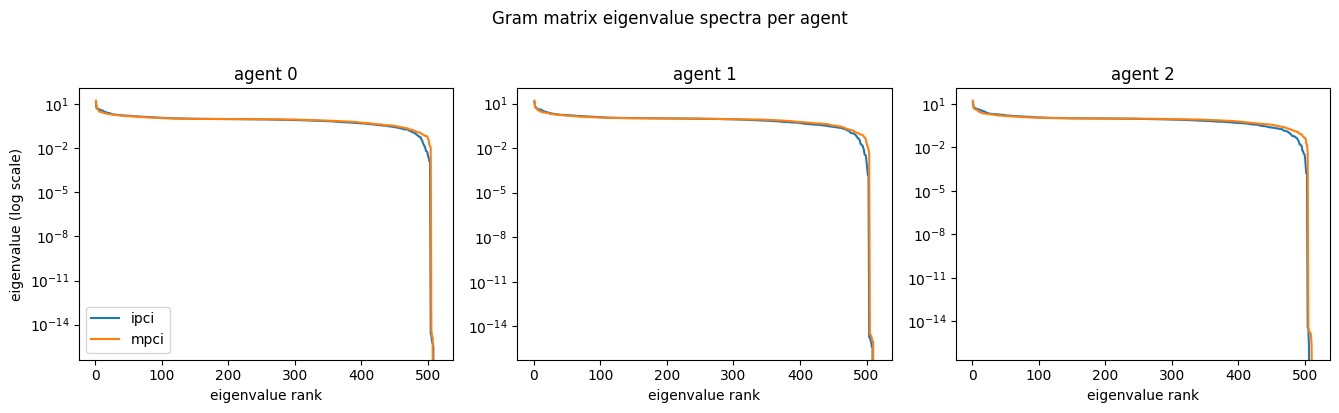

In [7]:
fig, axes = plt.subplots(1, num_agents, figsize=(4.5 * num_agents, 4), squeeze=False)
axes = axes[0]

for algo in algo_names:
    gram_pa = RESULTS[algo]["gram_pa"]
    for agent in range(num_agents):
        K_sym = 0.5 * (gram_pa[agent] + gram_pa[agent].T)
        eigvals = np.clip(np.linalg.eigvalsh(K_sym), a_min=0.0, a_max=None)[::-1]  # descending
        axes[agent].plot(np.arange(1, len(eigvals) + 1), eigvals, marker="", label=algo)
        axes[agent].set_yscale("log")
        axes[agent].set_title(f"agent {agent}")
        axes[agent].set_xlabel("eigenvalue rank")

axes[0].set_ylabel("eigenvalue (log scale)")
axes[0].legend()
fig.suptitle("Gram matrix eigenvalue spectra per agent", y=1.02)
plt.tight_layout()
plt.show()


## Bonus: per-feature component kernels before multiplication

`_compute_gram` standardizes each feature group (`z`, action one-hot, `x_obs`, bridge hidden context, bridge prev-action context) and computes an independent RBF kernel per group, then multiplies them together (`algorithms_jax/r_pci.py:1185-1245`). Those per-component kernels aren't returned by `_compute_gram` itself, so this cell re-implements the same standardization/RBF logic in plain numpy (read-only, notebook-local — `r_pci.py` is not modified) on the actual collected rollout data, to make the "standardize each feature block → RBF → multiply" pipeline visually concrete for agent 0.

ipci: max |re-derived product - gram_pa[0]| = 2.563e-06
mpci: max |re-derived product - gram_pa[0]| = 1.431e-06


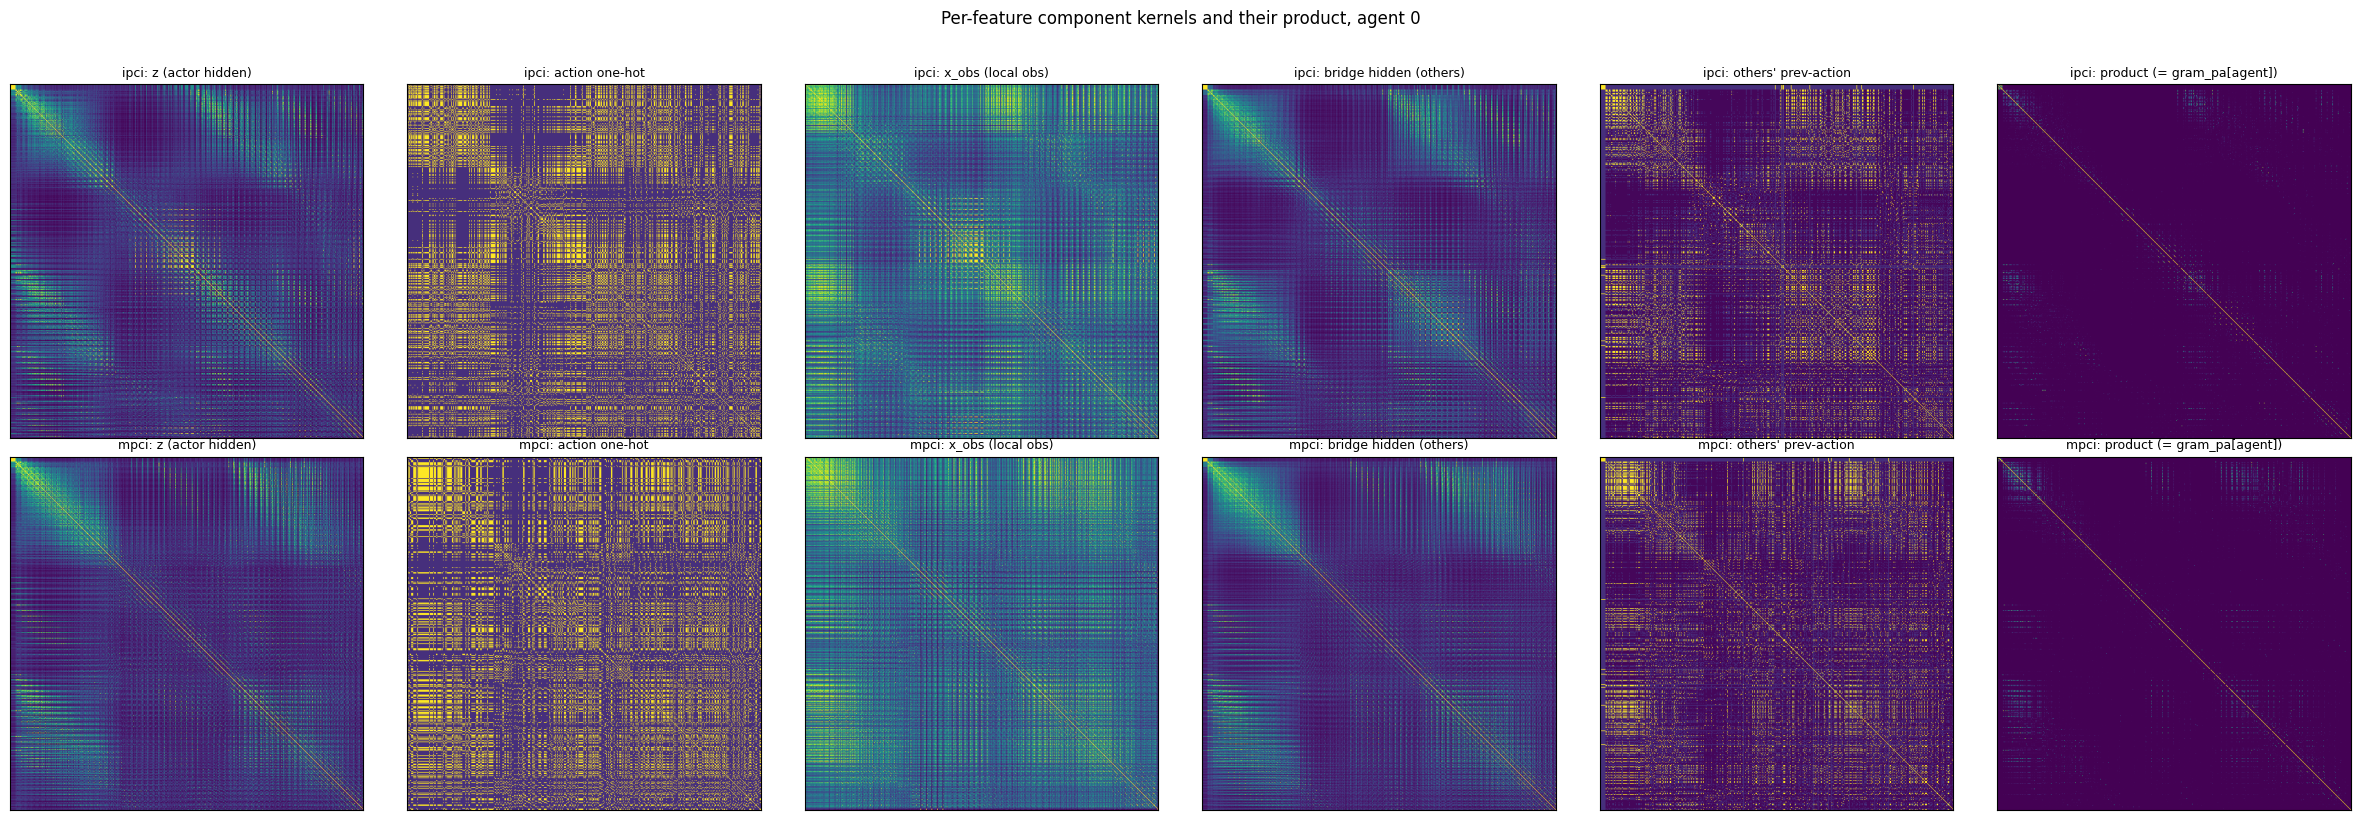

In [8]:
def split_per_agent(x: np.ndarray, N: int) -> np.ndarray:
    B = x.shape[0]
    B_n = B // N
    if x.ndim == 1:
        return x.reshape(B_n, N).T
    return x.reshape(B_n, N, x.shape[-1]).transpose(1, 0, 2)


def standardize_n(x_n: np.ndarray, mask_n: np.ndarray) -> np.ndarray:
    if x_n.shape[-1] == 0:
        return x_n
    count = max(mask_n.sum(), 1.0)
    mean = (mask_n[:, None] * x_n).sum(0) / count
    cx = x_n - mean
    var = (mask_n[:, None] * np.square(cx)).sum(0) / count
    return cx / np.sqrt(np.clip(var, 1.0e-6, None))


def rbf_gram(x: np.ndarray, gamma: float) -> np.ndarray:
    x_sq = np.sum(np.square(x), axis=-1, keepdims=True)
    dists_sq = np.clip(x_sq - 2.0 * (x @ x.T) + x_sq.T, 0.0, None)
    return np.exp(-gamma * dists_sq)


def component_kernels_for_agent(result: dict, agent: int = 0) -> dict:
    """Re-derive the per-feature-group RBF kernels that _compute_gram multiplies together."""
    batch_np = result["batch_np"]
    N = result["num_agents"]
    obs_dim = result["obs_dim"]
    bridge_hidden_dim = result["bridge_hidden_dim"]
    bridge_prev_action_dim = result["bridge_prev_action_dim"]

    z_pa = split_per_agent(batch_np["z"], N)
    xobs_pa = split_per_agent(batch_np["x_obs"], N)
    xhid_pa = split_per_agent(batch_np["x_hid"], N)
    mask_pa = split_per_agent(batch_np["loss_mask"], N)
    aoh_all = np.eye(result["action_dim"], dtype=np.float32)[batch_np["actions"].astype(int)]
    aoh_pa = split_per_agent(aoh_all, N)

    z_n, xobs_n, xhid_n, mask_n, aoh_n = (
        z_pa[agent], xobs_pa[agent], xhid_pa[agent], mask_pa[agent], aoh_pa[agent]
    )

    gamma_z = 1.0 / max(1, z_n.shape[-1])
    gamma_xobs = 1.0 / max(1, xobs_n.shape[-1])

    gamma_xhid = 1.0
    if bridge_hidden_dim > 0:
        xhid_hidden_all = batch_np["x_hid"][:, :bridge_hidden_dim]
        loss_mask_all = batch_np["loss_mask"]
        count_g = max(loss_mask_all.sum(), 1.0)
        mean_g = (loss_mask_all[:, None] * xhid_hidden_all).sum(0) / count_g
        cx_g = xhid_hidden_all - mean_g
        var_g = (loss_mask_all[:, None] * np.square(cx_g)).sum(0) / count_g
        xhid_norm_g = cx_g / np.sqrt(np.clip(var_g, 1.0e-6, None))
        eff_dim = np.mean(np.sum(np.abs(xhid_norm_g) > 1.0e-6, axis=-1))
        gamma_xhid = 1.0 / max(eff_dim, 1.0)

    z_norm_n = standardize_n(z_n, mask_n)
    xobs_cont_n = standardize_n(xobs_n[:, :obs_dim], mask_n)
    xobs_norm_n = np.concatenate([xobs_cont_n, xobs_n[:, obs_dim:]], axis=-1)

    components = {
        "z (actor hidden)": rbf_gram(z_norm_n, gamma_z),
        "action one-hot": rbf_gram(aoh_n, 1.0),
        "x_obs (local obs)": rbf_gram(xobs_norm_n, gamma_xobs),
    }
    if bridge_hidden_dim > 0:
        xhid_h_n = standardize_n(xhid_n[:, :bridge_hidden_dim], mask_n)
        components["bridge hidden (others)"] = rbf_gram(xhid_h_n, gamma_xhid)
    if bridge_prev_action_dim > 0:
        components["others' prev-action"] = rbf_gram(xhid_n[:, bridge_hidden_dim:], 1.0)

    valid_n = mask_n[:, None] * mask_n[None, :]
    product = valid_n.copy()
    for K_component in components.values():
        product = product * K_component
    components["product (= gram_pa[agent])"] = product
    return components


AGENT_FOR_BREAKDOWN = 0
fig, axes = plt.subplots(
    len(algo_names), 6, figsize=(4 * 6, 4 * len(algo_names)), squeeze=False
)
for row, algo in enumerate(algo_names):
    comps = component_kernels_for_agent(RESULTS[algo], agent=AGENT_FOR_BREAKDOWN)
    for col, (name, K_mat) in enumerate(comps.items()):
        ax = axes[row][col]
        ax.imshow(K_mat, cmap="viridis", vmin=0.0, vmax=1.0)
        ax.set_title(f"{algo}: {name}", fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])
    # Sanity check: the re-derived product should match _compute_gram's own gram_pa for this agent.
    max_abs_diff = np.max(np.abs(comps["product (= gram_pa[agent])"] - RESULTS[algo]["gram_pa"][AGENT_FOR_BREAKDOWN]))
    print(f"{algo}: max |re-derived product - gram_pa[{AGENT_FOR_BREAKDOWN}]| = {max_abs_diff:.3e}")

fig.suptitle(f"Per-feature component kernels and their product, agent {AGENT_FOR_BREAKDOWN}", y=1.02)
plt.tight_layout()
plt.show()


## Analysis

**Composite Gram matrices are nearly diagonal.** Across all 3 agents and both checkpoints, the average off-diagonal kernel value is tiny — `Kz_offdiag_mean` ≈ 0.0053 (ipci) / 0.0061 (mpci), std ≈ 0.04. On a `[0,1]` color scale (matching the diagonal's value of 1) the heatmaps are essentially a bright diagonal line on a uniformly dark background.

**Masking the diagonal and rescaling reveals real off-diagonal structure.** Pooled across both algorithms and all agents, off-diagonal values average 0.0055 but range up to 0.998 — a small number of sample pairs are genuinely (near-)identical under the full product kernel. Rescaling the color map to the 99th percentile of off-diagonal values (≈0.118) and masking the diagonal to white shows: (1) a soft band of elevated similarity immediately around the main diagonal — nearby timesteps within the same episode are more alike than distant ones, as expected from the smooth `z`/`x_obs` component kernels below; (2) a faint periodic grid with period equal to `n_envs=8` — since the flattened batch index is `t*n_envs + e`, same-env samples recur every 8 positions, so each environment's own trajectory carries a bit more self-similarity over time than cross-env pairs; (3) a handful of sparse, near-1 bright outlier points — isolated pairs of samples (different env/time combinations) that happen to land almost exactly on top of each other in the full 5-feature product-kernel space (e.g. similar early-game spawn configurations, or repeated idle/no-attack states).

**Eigenvalue spectrum ↔ rank.** For a symmetric PSD matrix, algebraic rank = number of strictly-positive eigenvalues, so the spectrum plot's "cliff" is literally a picture of the matrix's rank deficiency. We verified this precisely (re-deriving eigenvalues in float64 on the host, since JAX's float32 GPU `eigvalsh` leaves residual noise — see caveat below): out of `B_n=512` samples per agent, exactly **9 (ipci) / 8 (mpci)** carry `loss_mask=0` (post-episode-end padding). `K_n = K_n * valid_n` ([r_pci.py:1243](../algorithms_jax/r_pci.py#L1243)) zeroes those samples' entire row *and* column, which is an exact, mechanical source of rank deficiency — and indeed the float64 recompute shows a clean, sharp jump: the `512 - masked` "real" eigenvalues range continuously from the top eigenvalue (~12–17) down to a smallest real value of only ~1e-4–1e-3, then there is a six-order-of-magnitude drop straight to the masked eigenvalues (~1e-15–1e-16, i.e. floating-point noise around exact 0). So **numerical rank = `B_n − masked_count` exactly** — masking alone fully explains the rank deficiency; no additional near-duplicate *valid* samples are involved (despite the near-1 outlier pairs noted above — those raise off-diagonal similarity locally but aren't strong enough to make a sample's row exactly linearly dependent on another's).

*Caveat on the condition-number metrics:* `K_eig_min_pos_mean`/`K_eig_log_condition_mean` are computed by `_compute_gram` using JAX's float32 GPU `eigvalsh`, which can't push the masked/zero eigenvalues all the way to exact 0 — it leaves residual noise around 1e-7–1e-8 that slips past the code's `eigvals > 1e-8` "positive" filter ([r_pci.py:1283-1284](../algorithms_jax/r_pci.py#L1283-L1284)) and gets reported as the "smallest positive eigenvalue." A float64 recompute shows the true smallest *real* eigenvalue is ~1e-4–1e-3, four orders of magnitude larger. So the reported `K_eig_log_condition_mean` ≈ 19 (implied condition number ~1e8) overstates the ill-conditioning of the genuinely-informative part of the spectrum — the "real" (non-masked) part of the kernel is closer to a condition number of ~1e5. This doesn't change the qualitative conclusion (the raw `gram_pa` is singular along the masked directions and needs the Tikhonov ridge to be solvable), but it does mean the *reported* condition-number metric is partly a float32-precision artifact rather than a purely data-driven quantity.

**Effective rank is a *softer* notion than numerical rank, and it's noticeably lower.** `K_effective_rank_mean` ≈ 384 (ipci) / 400 (mpci) — this is `exp(entropy of the normalized eigenvalue distribution)`, not a count of nonzero eigenvalues. It's meaningfully below the numerical rank (~503/504) because the eigenvalue mass isn't spread perfectly evenly: the single largest eigenvalue alone carries ~2.4–3.3% of the total spectral mass (`K_eig_top1_frac_mean`), versus ~0.2% under a perfectly uniform spread across ~503 nonzero eigenvalues. So even restricted to the "real" (unmasked) eigenvalues, there's a mild concentration of spectral mass in a few leading directions — consistent with the diagonal-adjacent band and periodic per-env structure visible in the off-diagonal-only heatmap above.

**The per-feature breakdown (agent 0) shows where the off-diagonal sparsity comes from.** Individually, `z` (actor hidden), `x_obs`, and the bridge-hidden block all show smooth, broad similarity bands near the diagonal (nearby timesteps within the same episode genuinely look similar) — informative kernels on their own. The discrete one-hot kernels (`action`, `others' prev-action`) instead show a blocky/patchy structure (same-action pairs match regardless of time). But the *product* of all five collapses almost entirely onto the diagonal: even moderate per-factor similarity (five factors ≈0.5 each) multiplies down to ≈0.03.

This points the earlier standardization-vs-unit-norm discussion in a different direction: the dominant cause of the composite kernel's off-diagonal sparsity here is structural — multiplying ~5 independent RBF factors together — not the specific per-feature normalization scheme. Swapping standardization for unit-norm would reshape each factor individually, but wouldn't change the fact that multiplying several sub-1 factors compounds toward zero; the off-diagonal collapse would likely persist either way.

**ipci vs mpci are similar, with mpci marginally less sparse / better conditioned.** mpci (centralized critic) shows slightly higher off-diagonal mean/std, slightly higher effective rank, and a slightly lower log-condition number than ipci (decentralized critic) — consistent with mpci's centralized critic seeing more shared/correlated state across agents — but the gap is small relative to the shared qualitative picture: both checkpoints produce a near-identity composite kernel whose rank deficiency is exactly explained by episode-end masking, with a mild eigenvalue concentration on top.